### Foreplay ###

In [2]:
import numpy as np
import pandas as pd
from scipy.linalg import eigh
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from datetime import datetime


In [3]:
# Match plots to Latex style
plt.rcParams.update({
    "mathtext.fontset": "cm",               # Computer modern for math
    "font.family": "serif",
    "font.serif": ["cmr10"],                # Computer modern roman
    "axes.formatter.use_mathtext": True,    # math formatting
})


### Load Data ###

In [4]:
# Route to data
datadir = 'DATA/'
train_data = 'train.npz'
test_data = 'test.npz'

# Open training data
training = np.load(datadir + train_data)
test = np.load(datadir + test_data)

# Extract variables
X       = training['X']         # Patch data (18900, 64, 64, 13)
Y       = training['y']         # Labels (18900,)
classes = training['classes']   # Class list (10,)
bands   = training['bands']     # Band list (13,)

N = X.shape[0]              # Number of patches (18900)
P = X.shape[1:3]            # Patch dimensions (64,64)
D = len(bands)              # Number of bands (13)
C = len(classes)            # Number of classes (10)

X_test_true     = test['X']
classes_test    = training['classes']       # Class list (10,)
bands_test      = training['bands']         # Band list (13,)
ids             = test['id']                # Test sample ids (8100,)
N_test          = X_test_true.shape[0]      # Number of patches (18900)
P_test          = X_test_true.shape[1:3]    # Patch dimensions (64,64)
D_test          = len(bands_test)           # Number of bands (13)
C_test          = len(classes_test)         # Number of classes (10)


### Function Definitions ###

In [5]:
class LDA:
    def __init__(self):
        pass

    # Implement fisherLDA with Euclidean classification (from scratch)
    def fit(self, X, Y):
        # INPUT:
        #   X           : (N,C) matrix of data points
        #   Y           : (N,) vector of labels
        #
        # RETURNS:
        #   self        : Fitted model

        # Characterize dataset
        N = X.shape[0]                  # Number of samples
        D = X.shape[-1]                 # Number of bands
        self.classes = np.unique(Y)     # Class list
        C = len(self.classes)           # Number of classes

        # Validate inputs
        if X.ndim != 2:             # Check X dimensionality
            raise ValueError(f'Incorrect X dimensions: expected (N,2); received {X.shape}')
        if Y.ndim != 1:             # Check Y dimensionality
            if Y.ndim==2 and min(Y.shape) == 1:     # Remedy 2 dimensional Y if (N,1)
                Y = Y.reshape(-1)
            else:
                raise ValueError(f'Incorrect Y dimensions: expected ({N},); received {Y.shape}')
        if len(Y) != N:             # Check X and Y lengths match
            raise ValueError(f'X and Y sizes do not agree: X contains {N} samples but Y contains {len(Y)} labels')

        # Data means/centroids
        grand_mean = X.mean(axis=0)                                         # Grand means (D,)
        class_mean = np.array([ X[Y==c].mean(axis=0) for c in range(C)])    # Class means (C,D)

        # Between class scatter matrix
        Sb = (class_mean - grand_mean).T @ (class_mean - grand_mean)    # (D,D)

        # Within class scatter matrix
        Sw = np.zeros_like(Sb)      # (D,D)
        for c in range(C):
            Sw += (X[Y==c] - class_mean[c]).T @ (X[Y==c] - class_mean[c])

        # Eigenvalue decomposition
        eigvals, eigvecs = eigh(Sb, Sw)

        # Sort by eigenvals
        order = np.argsort(eigvals)[::-1] # Descending order
        eigvals = eigvals[order]
        eigvecs = eigvecs[:, order]

        M = np.count_nonzero(eigvals)   # Use all nonzero directions, at most C-1
        self.W = eigvecs[:,:M]          # Projection matrix into Fisher space

        X_F = X @ self.W                # Project training data to Fisher space (n_train,M)

        # Class means in Fisher space
        self.class_mean_F = np.array([ X_F[Y==c].mean(axis=0) for c in range(C)])  # (C,M)

        return self


    def predict(self, X):
    # Classify test data by Euclidean distance
        N = X.shape[0]              # Number of samples
        C = len(self.classes)       # Number of classes
        X_F = X @ self.W            # Project test data to Fisher space
        Y_idx = np.empty(N, dtype=int)
        for n in range(X.shape[0]):
            dists = [np.sum((X_F[n,:] - self.class_mean_F[c])**2) for c in range(C)]    # Distance of data points to class centroids
            Y_idx[n] = np.argmin(dists)                                                 # Assign data points to nearest class centroid

        return self.classes[Y_idx]
            

def cmAccuracy(cm):
# Evaluate classification accuracy by confusion matrix 
    cm = np.asarray(cm)
    N = cm.sum()                                            # Total within matrix (for normalizing)
    po = np.trace(cm) / N                                   # Overall Accuracy
    pe = np.sum(cm.sum(axis=0) * cm.sum(axis=1)) / N**2     # Expected Agreement by Chance
    kappa = (po - pe) / (1 - pe)                            # Cohen's kappa
    return [po, pe, kappa]


def dispConfusion(confustion_matrix_test, confustion_matrix_train=None, accuracy=None, savefig='true', model_name=None):
    # INPUT:
    #   confustion_matrix_test      : Confustion matrix for test data
    #   confustion_matrix_train     : Confustion matrix for test data
    #   accuracy                    : List of [overall accuracy, expected agreeement by chance, Cohen's kappa]
    #                                 If confustion_matrix_train provided, accuracy must be dict of {'Training','Test'}

    checkNorm = lambda cm: '0.2f' if cm.max()<=1 else '0.0f'    # Check if confusion matrix is normalized, format numbers accordingly

    if confustion_matrix_train is None:

        fig = plt.figure(figsize=[8,8])
        ax = plt.subplot(1,1,1)
        sns.heatmap(confustion_matrix_test, square=True, annot=True, cmap="rocket_r", cbar=False,
                    fmt=checkNorm(confustion_matrix_test), annot_kws={'fontsize': 16})
        ax.set_xlabel('Predicted', labelpad=10, fontsize=20)
        ax.set_ylabel('True', labelpad=10, fontsize=20)
        ax.tick_params(axis='both', labelsize=16)
        if accuracy is None:
            ax.set_title('Test', fontsize=24, pad=10)
        else:
            ax.set_title('Test', fontsize=24, pad=30)
            ax.text(3.1,-0.15,fr'$p_o = {100*accuracy[0]:0.1f}$%, $\kappa = {100*accuracy[2]:0.1f}$%', fontsize=16)

    else:
        fig = plt.figure(figsize=[16,8])
        ax = plt.subplot(1,2,1)
        sns.heatmap(confustion_matrix_train, square=True, annot=True, cmap="rocket_r", cbar=False,
                    fmt=checkNorm(confustion_matrix_train), annot_kws={'fontsize': 16})
        ax.set_xlabel('Predicted', labelpad=10, fontsize=20)
        ax.set_ylabel('True', labelpad=10, fontsize=20)
        ax.tick_params(axis='both', labelsize=16)
        if accuracy is None:
            ax.set_title('Training', fontsize=24, pad=10)
        else:
            ax.set_title('Training', fontsize=24, pad=30)
            ax.text(3.1,-0.15,fr"$p_o = {100*accuracy['Training'][0]:0.1f}$%, $\kappa = {100*accuracy['Training'][2]:0.1f}$%", fontsize=16)

        ax = plt.subplot(1,2,2)
        sns.heatmap(confustion_matrix_test, square=True, annot=True, cmap="rocket_r", cbar=False,
                    fmt=checkNorm(confustion_matrix_test), annot_kws={'fontsize': 16})
        ax.set_xlabel('Predicted', labelpad=10, fontsize=20)
        ax.set_ylabel('True', labelpad=10, fontsize=20)
        ax.tick_params(axis='both', labelsize=16)
        if accuracy is None:
            ax.set_title('Test', fontsize=24, pad=10)
        else:
            ax.set_title('Test', fontsize=24, pad=30)
            ax.text(3.1,-0.15,fr"$p_o = {100*accuracy['Test'][0]:0.1f}$%, $\kappa = {100*accuracy['Test'][2]:0.1f}$%", fontsize=16)

    if savefig == 'true':
        if model_name is None:
            model_name = datetime.now().strftime("%Y-%m-%d_%H:%M")
        figname = 'CM_'+model_name+'.png'
        fig.savefig(figname, dpi=500, bbox_inches='tight')


def pcaAnalysis(variance):
    fig = plt.figure(figsize=(12,6))
    ax = plt.axes()
    ax.plot(np.arange(len(variance))+1, variance, lw=2)
    ax.set_title('PCA: Explained Variance', fontsize=18)
    ax.set_xlabel('PC', fontsize=16)
    ax.set_ylabel(r'$\sigma$', rotation=0, fontsize=16, labelpad=10)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=12)
    ax.grid()
    return


def createSubmissionFile(ids, Ypred, classes):
    Yclass = classes[Ypred]
    submission_df = pd.DataFrame({"id": ids, "label": Yclass})
    submission_df.to_csv("AyPeter_classified_samples.csv", index=False)
    return

### Run Models ###

Preparing data...
	 complete
Running PCA...
	 complete
Running LDA...
	 complete
Running RF...
	 complete


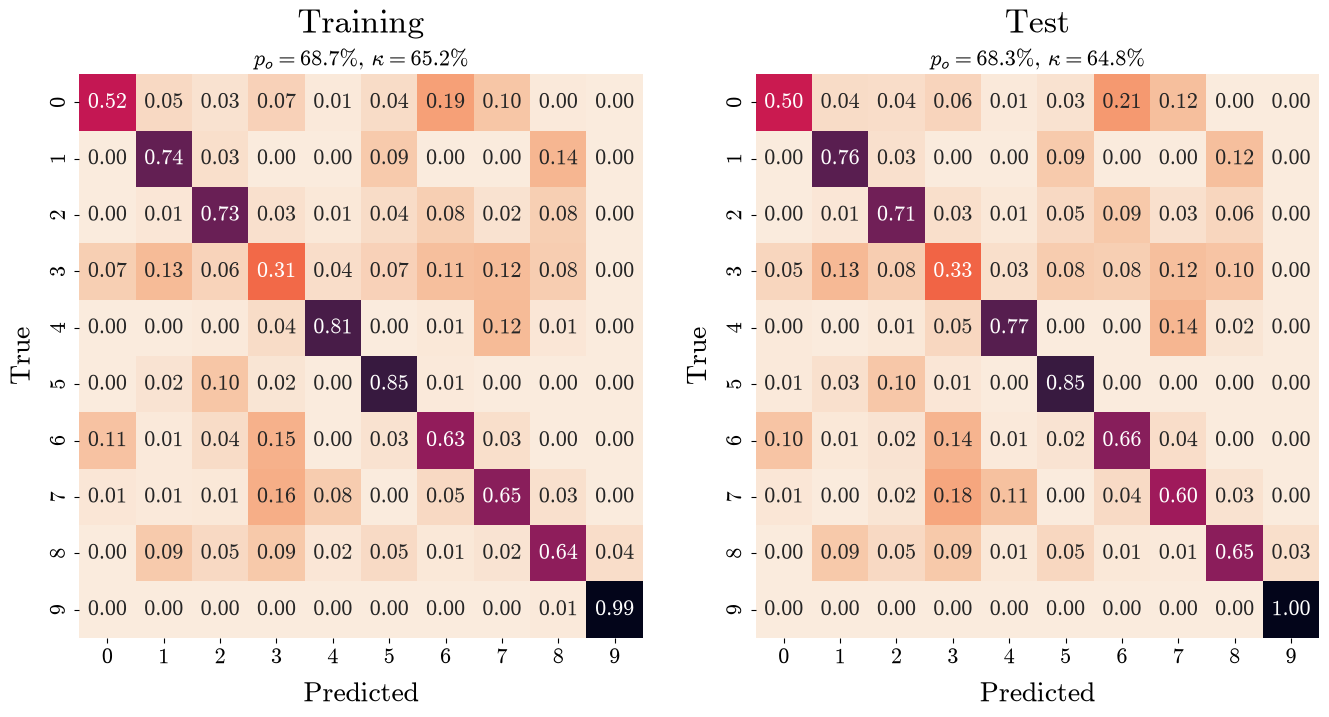

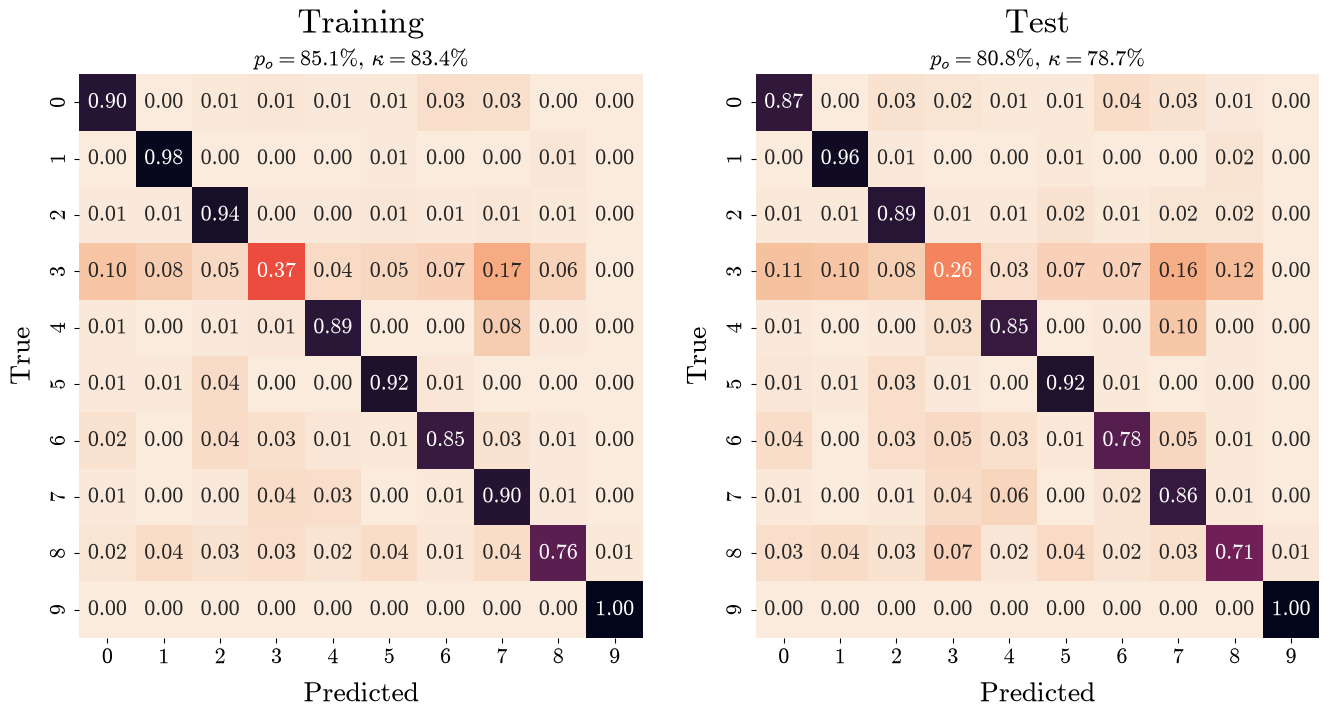

In [ ]:
# Model parameters
tr_ratio        = 0.7       # Fraction of data used for training. Ignored if implement_model is not None
implement_model = None      # Which model to classify provided test samples with
runPCA          = True      # Perform PCA dimensionality reduction (boolean)
runLDA          = True     # Perform LDA classification (boolean)
runRF           = True      # Perform RF classification (boolean)

# Visualization parameters
cm_norm         = 'true'    # Normalize confusion matrix
savefigs        = 'true'    # Save generated figures locally

# PCA parameters
unit_scale      = True      # Scale data to unite variance prior to PCA
n_components    = None      # Number of PCs to retain
whiten          = True      # Whiten data
solver          = 'auto'    # SVD solver
tol             = 0.0       # Tolerance to which PCs are solved
analyzePCA      = False     # Produce component analysis (boolean)


# Random Forest parameters
n_trees         = 500       # Number of trees
n_jobs          = -1        # Number of jobs to run in parallel
impurity        = 'gini'    # Impurity criterion used to evaluate splits {'gini', 'entropy', 'log_loss'}
max_depth       = None      # Maximum tree depth
n_features      = 'sqrt'    # Number of features available for each split
bootstrap       = True      # Bootstrap subsets from data
n_bootstrap     = 0.7       # Number of samples in bootstrapped data
min_n_leaf      = 2         # Minimum number of samples required to be at a leaf node
oob             = False     # Evaluate Out of Bag scores
ccp_alpha       = 0.0008    # Complexity coefficient for pruning

# Prepare data
print('Preparing data...')
X_flat = np.array([X[patch].reshape(np.prod(P),D).mean(axis=0) for patch in range(N)]) # Downsample (average patches)
if implement_model is None:
    X_train, X_test, Y_train, Y_test = train_test_split(X_flat, Y, train_size=tr_ratio, random_state=99)   # Train-test split
else:
    X_train, Y_train = X_flat, Y
    X_test_flat = np.array([X_test_true[patch].reshape(np.prod(P_test),D_test).mean(axis=0) for patch in range(N_test)]) # Downsample (average patches)
    X_test = X_test_flat
print('\t complete')

# Run PCA
if runPCA:
    print('Running PCA...')
    scaler = StandardScaler(with_std=unit_scale).fit(X_train)
    X_train = scaler.transform(X_train)
    X_test = scaler.transform(X_test)
    pca = PCA(n_components=n_components, whiten=whiten, tol=tol, svd_solver=solver)
    pca.fit(X_train)
    X_train = pca.transform(X_train)
    X_test = pca.transform(X_test)
    if analyzePCA:
        pcaAnalysis(pca.explained_variance_)
    print('\t complete')

# Run LDA
if runLDA:
    print('Running LDA...')
    # Create LDA model
    lda = LDA()

    # Fit model
    lda.fit(X_train, Y_train)

    # Predict on training and test data
    Ytrain_pred = lda.predict(X_train)
    Ytest_pred = lda.predict(X_test)

    if implement_model == 'LDA':
        print('\t Saving submission file...')
        createSubmissionFile(ids, Ytest_pred)
    elif implement_model is None:
        # Evaluate classification
        cm_train = confusion_matrix(Y_train, Ytrain_pred, normalize=cm_norm)
        cm_test = confusion_matrix(Y_test, Ytest_pred, normalize=cm_norm)
        acc_train = cmAccuracy(cm_train)
        acc_test = cmAccuracy(cm_test)
        model_name = 'LDA_PCA' if runPCA else 'LDA'
        dispConfusion(cm_test, cm_train,
                    accuracy={'Training': acc_train, 'Test': acc_test},
                    savefig=savefigs, model_name=model_name)
    print('\t complete')

# Run RF
if runRF:
    print('Running RF...')
    # Create RF model
    rf = RandomForestClassifier(n_estimators=n_trees,
                                n_jobs=n_jobs,
                                criterion=impurity,
                                max_depth=max_depth,
                                max_features=n_features,
                                bootstrap=bootstrap,
                                max_samples=n_bootstrap,
                                min_samples_leaf=min_n_leaf,
                                oob_score=oob,
                                ccp_alpha=ccp_alpha)

    # Fit model
    rf.fit(X_train, Y_train)

    # Predict on training and test data
    Ytrain_pred = rf.predict(X_train)
    Ytest_pred = rf.predict(X_test)
    proba = rf.predict_proba(X_test)       # Estimated probability for each class
    confidence = proba.max(axis=1)         # Confidence
    # print(f'\t RF Confidence: {confidence*100:0.2f}\%')


    if implement_model == 'RF':
        print('\t Saving submission file...')
        createSubmissionFile(ids, Ytest_pred, classes)
    elif implement_model is None:
        # Evaluate classification
        cm_train = confusion_matrix(Y_train, Ytrain_pred, normalize=cm_norm)
        cm_test = confusion_matrix(Y_test, Ytest_pred, normalize=cm_norm)
        acc_train = cmAccuracy(cm_train)
        acc_test = cmAccuracy(cm_test)
        model_name = 'RF_PCA' if runPCA else 'RF'
        dispConfusion(cm_test, cm_train,
                    accuracy={'Training': acc_train, 'Test': acc_test},
                    savefig=savefigs, model_name=model_name)
    print('\t complete')


### Random Forest: Accuracy vs Tree Depth and CCP Coefficient ###

In [ ]:
# Train and test RF across spread of variables
def tuneRFparams(params, var1, var1vals, var2, var2vals):
    kappa_train = np.zeros((len(var1vals), len(var2vals)))
    kappa_test = np.zeros((len(var1vals), len(var2vals)))

    for n1 in range(len(var1vals)):
        print(f'{n1} \t : ', end='')
        params[var1] = var1vals[n1]
        for n2 in range(len(var2vals)):
            print(f' {n2},', end='')
            params[var2] = var2vals[n2]
            rf = RandomForestClassifier(n_estimators=params['n_trees'],
                                            n_jobs=params['n_jobs'],
                                            criterion=params['impurity'],
                                            max_depth=params['max_depth'],
                                            max_features=params['n_features'],
                                            bootstrap=params['bootstrap'],
                                            max_samples=params['n_bootstrap'],
                                            min_samples_leaf=params['min_n_leaf'],
                                            oob_score=params['oob'],
                                            ccp_alpha=params['ccp_alpha'])
            
            # Fit model
            rf.fit(X_train, Y_train)

            # Predict on training and test data
            Ytrain_pred = rf.predict(X_train)
            Ytest_pred = rf.predict(X_test)
            cm_train = confusion_matrix(Y_train, Ytrain_pred, normalize=cm_norm)
            cm_test = confusion_matrix(Y_test, Ytest_pred, normalize=cm_norm)
            _,_,kappa_train[n1,n2] = cmAccuracy(cm_train)
            _,_,kappa_test[n1,n2] = cmAccuracy(cm_test)
            if n2 == len(var2vals)-1:
                print(f'\t done')

    # Plot results

    # Test accuracy
    fig = plt.figure(figsize=(14,6))
    ax = plt.subplot(1,2,1)
    pm = ax.pcolormesh(var1vals, var2vals, 100*kappa_test.T,
                cmap='rocket')
    ax.set_xlabel(var1, fontsize=14)
    ax.set_ylabel(var2, fontsize=14)
    ax.set_title(r'Test $\kappa$ (%)', fontsize=16)
    cb = fig.colorbar(pm)
    # cb.set_label(r'$\kappa$ (%)', rotation=0, labelpad=20)

    # Fit assessment
    ax = plt.subplot(1,2,2)
    fit = (kappa_train - kappa_test) / kappa_test
    pm = ax.pcolormesh(var1vals, var2vals, 100*fit.T,
                cmap='rocket_r')
    ax.set_xlabel(var1, fontsize=14)
    ax.set_ylabel(var2, fontsize=14)
    ax.set_title(r'Train and test $\kappa$ disparity (% $\kappa_\text{test}$)', fontsize=16)
    cb = fig.colorbar(pm)
    # cb.set_label(r'$\kappa$ (%)', rotation=0, labelpad=20)

    fig.savefig(f'kappa_{var1}_vs_{var2}.png', dpi=300, bbox_inches='tight')

    return kappa_train, kappa_test

# Random Forest parameters
rf_params = {'n_trees'         : 25,        # Number of trees
             'n_jobs'          : -1,        # Number of jobs to run in parallel
             'impurity'        : 'gini',    # Impurity criterion used to evaluate splits {'gini', 'entropy', 'log_loss'}
             'max_depth'       : None,      # Maximum tree depth
             'n_features'      : 'sqrt',    # Number of features available for each split
             'bootstrap'       : True,      # Bootstrap subsets from data
             'n_bootstrap'     : 0.7,       # Number of samples in bootstrapped data
             'min_n_leaf'      : 2,         # Minimum number of samples required to be at a leaf node
             'oob'             : False,     # Evaluate Out of Bag scores
             'ccp_alpha'       : 0.0008,    # Complexity coefficient for pruning
}

depths = np.arange(4,30,2)
alphas = np.linspace(0.0001,0.001,20)
kappa_train, kappa_test = tuneRFparams(rf_params, 'max_depth', depths, 'ccp_alpha', alphas)

0 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
1 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
2 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
3 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
4 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
5 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
6 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
7 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
8 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
9 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
10 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
11 	 :  0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,	 done
12

### Random Forest: Accuracy vs Number of Trees ###

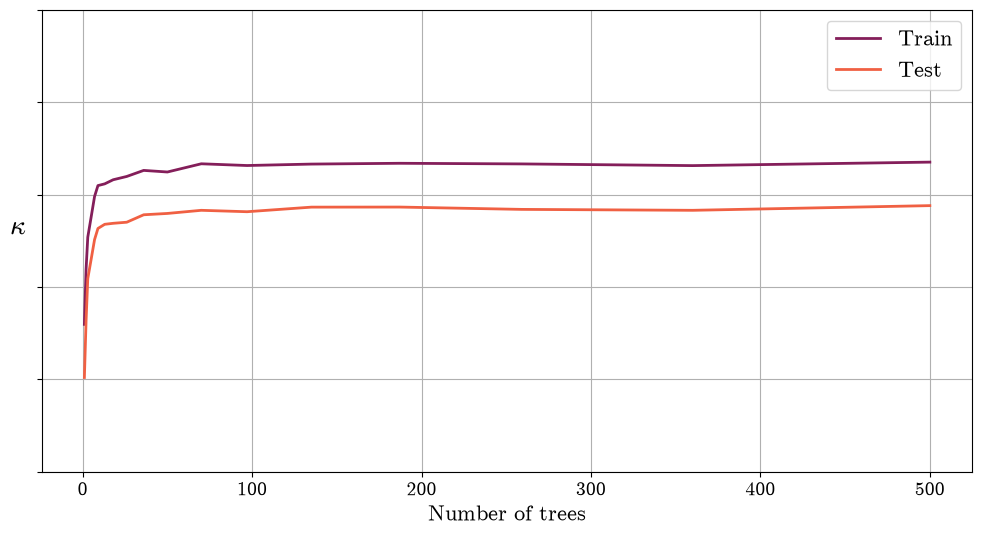

In [ ]:
# Random Forest parameters
n_trees = np.unique(np.geomspace(1, 500, num=20).astype(int))       # Number of trees
n_jobs          = -1        # Number of jobs to run in parallel
impurity        = 'gini'    # Impurity criterion used to evaluate splits {'gini', 'entropy', 'log_loss'}
max_depth       = None      # Maximum tree depth
n_features      = 'sqrt'    # Number of features available for each split
bootstrap       = True      # Bootstrap subsets from data
n_bootstrap     = 0.7       # Number of samples in bootstrapped data
min_n_leaf      = 2         # Minimum number of samples required to be at a leaf node
oob             = False     # Evaluate Out of Bag scores
ccp_alpha       = 0.0008    # Complexity coefficient for pruning

kappa_train_t   = np.zeros(len(n_trees))
kappa_test_t    = np.zeros(len(n_trees))

for n in range(len(n_trees)):
    rf = RandomForestClassifier(n_estimators=n_trees[n],
                                n_jobs=n_jobs,
                                criterion=impurity,
                                max_depth=max_depth,
                                max_features=n_features,
                                bootstrap=bootstrap,
                                max_samples=n_bootstrap,
                                min_samples_leaf=min_n_leaf,
                                oob_score=oob,
                                ccp_alpha=ccp_alpha)

    # Fit model
    rf.fit(X_train, Y_train)

    # Predict on training and test data
    Ytrain_pred = rf.predict(X_train)
    Ytest_pred = rf.predict(X_test)
    cm_train = confusion_matrix(Y_train, Ytrain_pred, normalize=cm_norm)
    cm_test = confusion_matrix(Y_test, Ytest_pred, normalize=cm_norm)
    _,_,kappa_train_t[n] = cmAccuracy(cm_train)
    _,_,kappa_test_t[n] = cmAccuracy(cm_test)

# Plot kappa vs n_trees
fig = plt.figure(figsize=(12,6))
ax = plt.axes()
colors = sns.color_palette("rocket", n_colors=2)
ax.set_prop_cycle(color=colors)
ax.plot(n_trees, 100*kappa_train_t, color=colors[0], lw=2, label='Train')
ax.plot(n_trees, 100*kappa_test_t, color=colors[1], lw=2, label='Test')
ax.legend(fontsize=16)
ax.set_ylabel(r'$\kappa$', rotation=0, labelpad=10, fontsize=20)
ax.set_xticks(np.arange(0,501,100))
ax.set_yticks(np.arange(50,101,10))
ax.set_xticklabels(np.arange(0,501,100), fontsize=14)
ax.set_yticklabels([])
# ax.set_yticklabels([f"{x:.0f}%" for x in np.arange(50,101,10)], fontsize=14)
ax.set_xlabel(r'Number of trees', fontsize=16)
ax.grid()

fig.savefig('RF_kappa_v_n.png', dpi=500, bbox_inches='tight')